In [5]:
pip install duckduckgo-search


Note: you may need to restart the kernel to use updated packages.


In [1]:
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from typing import Annotated, TypedDict, List
from langchain_core.messages import HumanMessage, BaseMessage
from langgraph.graph.message import add_messages

from langchain_community.tools import DuckDuckGoSearchRun
from langchain_core.tools import tool

from dotenv import load_dotenv
load_dotenv()

import requests

/tmp/ipykernel_154575/3979492781.py:8: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import DuckDuckGoSearchRun


In [2]:
llm = ChatOpenAI(model="gpt-4o-mini")

In [ ]:
# pip install -U ddgs

Note: you may need to restart the kernel to use updated packages.


In [4]:
# Tools
# pre-built tool
search_tool = DuckDuckGoSearchRun(region="us-en")

# custom tool
@tool
def calculator(first_num: float, second_num: float, operation: str) -> dict:
    """
    Perform a basic arithmetic operation on two numbers.
    Supported operations: add, sub, mul, div
    """
    try:
        if operation == "add":
            result = first_num + second_num
        elif operation == "sub":
            result = first_num - second_num
        elif operation == "mul":
            result = first_num * second_num
        elif operation == "div":
            if second_num == 0:
                return {"error": "Division by zero is not allowed"}
            result = first_num / second_num
        else:
            return {"error": f"Unsupported operation '{operation}'"}
        
        return {"first_num": first_num, "second_num": second_num, "operation": operation, "result": result}
    except Exception as e:
        return {"error": str(e)}


@tool
def get_stock_price(symbol: str) -> dict:
    """
    Fetch latest stock price for a given symbol (e.g. 'AAPL', 'TSLA') 
    using Alpha Vantage with API key in the URL.
    """
    url = f"https://www.alphavantage.co/query?function=GLOBAL_QUOTE&symbol={symbol}&apikey=R3PZAB0CGB0TY32I"
    r = requests.get(url)
    return r.json()

In [6]:
# Make tool list
tools = [search_tool, calculator, get_stock_price]

In [7]:
# binding all the tool
llm_with_tools = llm.bind_tools(tools)

In [8]:
class ChatState(TypedDict):
    messages: Annotated[List[BaseMessage], add_messages]

In [9]:
def chat_node(state: ChatState):
    """LLM node that may answer or request a tool call"""
    messages = state['messages']
    response = llm_with_tools.invoke(messages)
    return {'messages': [response]}

In [10]:
tool_node = ToolNode(tools)

In [11]:
graph = StateGraph(ChatState)
graph.add_node('chat_node', chat_node)
graph.add_node('tools', tool_node)

graph.add_edge(START, 'chat_node')
graph.add_conditional_edges('chat_node', tools_condition)

In [12]:
chatbot = graph.compile()

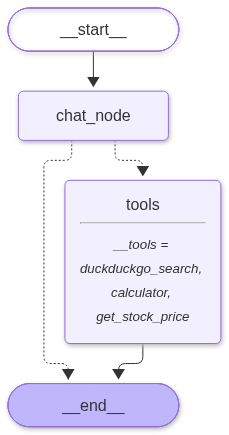

In [13]:
chatbot

In [15]:
output = chatbot.invoke({'messages': [HumanMessage(content= "What is the stock price of Tesla")]})
output['messages'][-1].content

'{"Global Quote": {"01. symbol": "TSLA", "02. open": "406.2500", "03. high": "406.5000", "04. low": "396.5300", "05. price": "398.5000", "06. volume": "26647733", "07. latest trading day": "2026-11-03", "08. previous close": "403.8200", "09. change": "-5.3200", "10. change percent": "-1.3174%"}}'

Two main problem:

    - No structured output
    - after tool calling we are directly heading towards end
    - We are not able to call two tools at one time (for eg- who is the owner of Youtube and what is the stock price of google?)

In [16]:
graph = StateGraph(ChatState)

graph.add_node('chat_node', chat_node)
graph.add_node('tools', tool_node)

graph.add_edge(START, 'chat_node')
graph.add_conditional_edges('chat_node', tools_condition)
graph.add_edge('tools', 'chat_node')

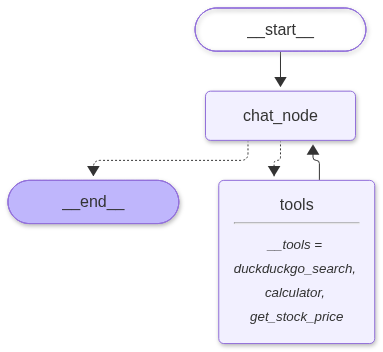

In [17]:
graph.compile()

In [18]:
chatbot = graph.compile()

In [19]:
output = chatbot.invoke({'messages': [HumanMessage(content= "What is the stock price of Apple and how much it will cost me if i purchase 20 stocks in INR")]})
output['messages'][-1].content

"The current stock price of Apple (AAPL) is $331.90. If you purchase 20 stocks, it will cost you $6,638. \n\nIf you'd like to convert this amount into Indian Rupees (INR), please provide the current exchange rate of USD to INR."